# Adaptive total fluxes across orbit classes

Increment D of the GPU/JAX port (`dev/PHASE5D.md`): one call --
`total_fluxes(orbit)` -- grows a batched (l, m, k, n) mode window in staged
rounds until the tower contributions fall below tolerance, for any bound
orbit. This demo runs the four orbit classes, shows the per-l-slab flux
breakdown and the round-by-round window growth, and a flux-vs-tolerance
staircase. Assertions embedded so re-execution is itself a test.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hblteuk.geo import MiniGeo
from hblteuk.jax import total_fluxes

orbits = {
    "circular":    MiniGeo(0.9, 10.0, 0.0, 1.0),
    "eccentric":   MiniGeo(0.9, 10.0, 0.2, 1.0),
    "spherical":   MiniGeo(0.9, 10.0, 0.0, 0.5),
    "generic":     MiniGeo(0.9, 8.0, 0.3, 0.6),
}
results = {}
# generic (2D torus) is by far the expensive class -- at tol < 1e-4 a
# strong-field orbit needs 100k+ modes; a coarser tol keeps the demo quick
# while the 1D/near-1D classes run at 1e-6
tols = dict(circular=1e-6, eccentric=1e-6, spherical=1e-6, generic=1e-4)
for name, orb in orbits.items():
    fx = total_fluxes(orb, tol=tols[name])
    results[name] = fx
    print(f"{name:11s}: Edot_inf = {fx.Edot[0]:.6e}, "
          f"Ldot_inf = {fx.Ldot[0]:.6e}, Qdot_inf = {fx.Qdot[0]:.6e}, "
          f"rounds = {len(fx.rounds)}, converged = {all(fx.converged.values())}")
    assert all(fx.converged.values())
    assert fx.Edot[0] > 0
# Carter flux vanishes on the two equatorial orbits
assert abs(results["circular"].Qdot[0]) < 1e-14
assert abs(results["eccentric"].Qdot[0]) < 1e-14

circular   : Edot_inf = 5.049094e-05, Ldot_inf = 1.642106e-03, Qdot_inf = -1.548173e-18, rounds = 5, converged = True


eccentric  : Edot_inf = 5.411551e-05, Ldot_inf = 1.628902e-03, Qdot_inf = 0.000000e+00, rounds = 5, converged = True


spherical  : Edot_inf = 5.421014e-05, Ldot_inf = 9.542075e-04, Qdot_inf = 9.080661e-03, rounds = 5, converged = True


generic    : Edot_inf = 1.873796e-04, Ldot_inf = 2.444663e-03, Qdot_inf = 1.460571e-02, rounds = 4, converged = True


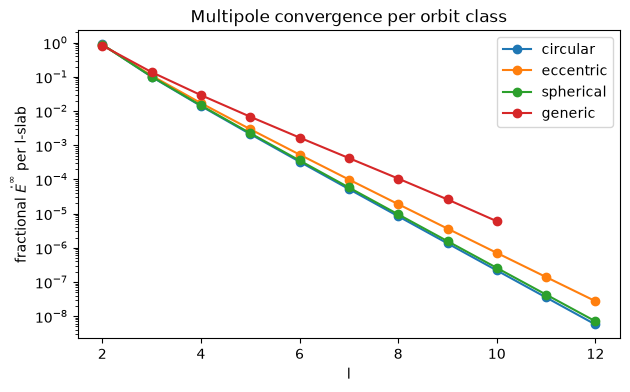

In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, fx in results.items():
    tab = fx.table
    ls = np.array(sorted(set(tab["l"].tolist())))
    slab = np.array([np.abs(tab["Edot"][tab["l"] == lv, 0]).sum() for lv in ls])
    ax.semilogy(ls, slab / slab.sum(), "o-", label=name)
ax.set_xlabel("l"); ax.set_ylabel(r"fractional $\dot{E}^\infty$ per l-slab")
ax.set_title("Multipole convergence per orbit class"); ax.legend()
plt.show()
# each tower falls off: the top slab is far below the l=2 peak
for fx in results.values():
    tab = fx.table
    ls = sorted(set(tab["l"].tolist()))
    top = np.abs(tab["Edot"][tab["l"] == ls[-1], 0]).sum()
    peak = np.abs(tab["Edot"][tab["l"] == ls[0], 0]).sum()
    assert top / peak < 1e-3

generic-orbit rounds:
  round 1: l<=4, |k|<=4, |n|<=5, +1038 modes, Edot_inf=1.849281e-04
  round 2: l<=6, |k|<=8, |n|<=10, +6992 modes, Edot_inf=1.872749e-04
  round 3: l<=8, |k|<=8, |n|<=10, +5711 modes, Edot_inf=1.873736e-04
  round 4: l<=10, |k|<=8, |n|<=10, +7139 modes, Edot_inf=1.873796e-04


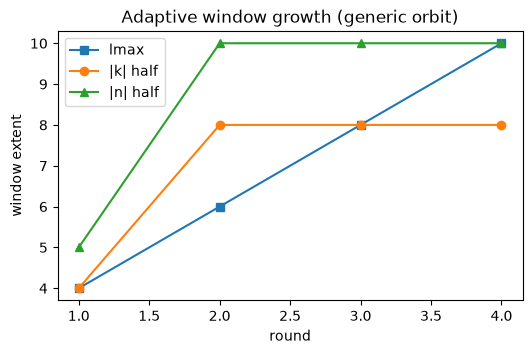

In [3]:
fx = results["generic"]
print("generic-orbit rounds:")
for i, rd in enumerate(fx.rounds, 1):
    lmax, kh, nh = rd["window"]
    print(f"  round {i}: l<={lmax}, |k|<={kh}, |n|<={nh}, "
          f"+{rd['n_new']} modes, Edot_inf={rd['totals']['Edot'][0]:.6e}")
windows = np.array([rd["window"] for rd in fx.rounds])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, len(fx.rounds) + 1), windows[:, 0], "s-", label="lmax")
ax.plot(range(1, len(fx.rounds) + 1), windows[:, 1], "o-", label="|k| half")
ax.plot(range(1, len(fx.rounds) + 1), windows[:, 2], "^-", label="|n| half")
ax.set_xlabel("round"); ax.set_ylabel("window extent"); ax.legend()
ax.set_title("Adaptive window growth (generic orbit)")
plt.show()

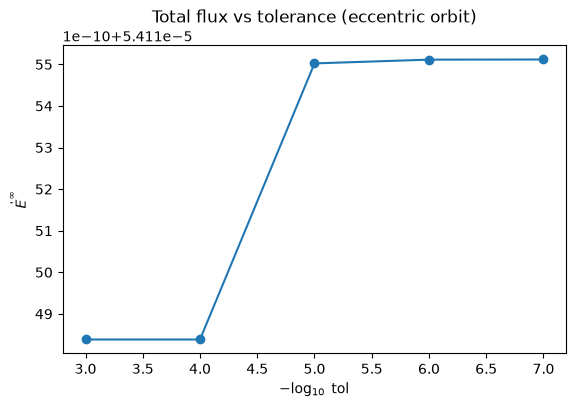

successive |Delta Edot|: [0.00000000e+00 6.64034769e-10 9.02308340e-12 3.53433191e-13]


In [4]:
orb = orbits["eccentric"]
tols = [1e-3, 1e-4, 1e-5, 1e-6, 1e-7]
vals, errs = [], []
for t in tols:
    fx = total_fluxes(orb, tol=t)
    vals.append(fx.Edot[0])
    errs.append(fx.error_bound[0, 0])   # E channel, infinity side
vals = np.array(vals); errs = np.array(errs)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(-np.log10(tols), vals, yerr=errs, fmt="o-", capsize=3)
ax.set_xlabel(r"$-\log_{10}$ tol"); ax.set_ylabel(r"$\dot{E}^\infty$")
ax.set_title("Total flux vs tolerance (eccentric orbit)")
plt.show()
# successive refinements shrink toward convergence: the last step is the
# smallest, and the finest two tolerances agree to well below 1e-6.
# (the coarsest diffs can be exactly 0 when two tols land on one window.)
diffs = np.abs(np.diff(vals))
print("successive |Delta Edot|:", diffs)
assert diffs[-1] <= diffs.max()
assert abs(vals[-1] - vals[-2]) / abs(vals[-1]) < 1e-6